# 电商订单数据集 —— 数据清洗（预处理）

## 1. 任务说明

本 Notebook 只做**数据清洗（预处理）**，不做业务分析，为后续的探索性分析（EDA）、建模做好准备。

- 数据来源：`ecommerce_orders_dataset.csv`（30,000 行 × 41 列）
- 字段说明：`data_dictionary.csv`
- 输出结果：`ecommerce_orders_cleaned.csv`（清洗后的数据文件）

## 2. 清洗流程

| 步骤 | 内容 |
| --- | --- |
| 1 | 字段核对（与数据字典比对）、`shape / info / describe` 概览 |
| 2 | 文本字段规范化（空格、大小写） |
| 3 | 数据类型转换与内存优化 |
| 4 | 缺失值分析 + 处理 |
| 5 | 重复值分析 + 去除 |
| 6 | 日期字段校验（一致性、未来日期） |
| 7 | 数值型异常值检测（IQR / 3σ / 分品类） |
| 8 | 业务逻辑一致性校验与修正 |
| 9 | 实体（客户/产品/城市）一致性检查 |
| 10 | 二值字段编码、衍生特征构造 |
| 11 | 清洗前后对比汇总、结果保存 |

> 约定：每一步只做一个功能，先由 Markdown 单元格说明思路，再由代码单元格实现。

## 3. 导入依赖库与运行环境设置

**实现功能**：导入 `pandas`、`numpy`、`matplotlib` 等数据处理常用库，设置 pandas 的显示参数（不省略列、统一小数位）与 matplotlib 的**中文字体**，避免后续图表中文乱码。

In [2]:
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore") # warnings 是 Python 自带的警告管理器；filterwarnings("ignore") 让所有警告（如中文字体缺失、FutureWarning）不再打印，避免刷屏，但不代表问题不存在

# ---------- pandas 显示设置 ----------
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# ---------- matplotlib 中文显示设置（Windows） ----------
mpl.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS", "Noto Sans CJK SC", "Source Han Sans SC", "WenQuanYi Zen Hei", "PingFang SC"]
mpl.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print(f"pandas 版本：{pd.__version__}")
print(f"numpy  版本：{np.__version__}")
print(f"matplotlib 版本：{mpl.__version__}")

pandas 版本：3.1.1
numpy  版本：2.5.4
matplotlib 版本：3.11.2


## 4. 读取数据并与数据字典核对字段

**实现功能**：
1. 使用 `pd.read_csv()` 读取订单数据，并**备份原始数据** `df_raw`（便于最后做清洗前后对比）。
2. 读取 `data_dictionary.csv`，核对「数据字段 ↔ 字典字段」是否一一对应，确认没有多余/遗漏字段。
3. 输出每个字段的含义、数据类型、非空值数量、唯一值数量，形成字段台账（后续所有步骤的检查依据）。

In [6]:
from pathlib import Path

# Notebooks live in notebooks/; datasets live in <root>/data/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "ecommerce_orders_dataset.csv"
DICT_PATH = ROOT / "data" / "data_dictionary.csv"

# 原始数据（不做任何修改，仅用于清洗前后对比）
df_raw = pd.read_csv(DATA_PATH)
# 工作副本：后续所有清洗操作都作用在 df 上
df = df_raw.copy()

data_dict = pd.read_csv(DICT_PATH)

print(f"原始数据规模：{df.shape[0]:,} 行 × {df.shape[1]} 列")
print(f"数据字典字段数：{len(data_dict)}\n")

missing_in_dict = sorted(set(df.columns) - set(data_dict["Column"]))
missing_in_data = sorted(set(data_dict["Column"]) - set(df.columns))
print("① 数据中存在、字典未记录的字段：", missing_in_dict or "无")
print("② 字典中存在、数据中缺失的字段：", missing_in_data or "无")

# 字段台账：含义 + 数据类型 + 非空数量 + 唯一值数量
field_info = data_dict[["Column", "Description"]].copy()
field_info["数据类型"] = field_info["Column"].map(df.dtypes.astype(str))
field_info["非空值数量"] = field_info["Column"].map(df.notna().sum())
field_info["唯一值数量"] = field_info["Column"].map(df.nunique())
field_info.head(10)

原始数据规模：30,000 行 × 41 列
数据字典字段数：41

① 数据中存在、字典未记录的字段： 无
② 字典中存在、数据中缺失的字段： 无


,Column,Description,数据类型,非空值数量,唯一值数量
0,Order_ID,Unique order identifier,int64,30000,30000
1,Customer_ID,Unique customer identifier,str,30000,8683
2,Order_Date,Date when the order was placed,str,30000,1461
3,Year,Order year,int64,30000,4
4,Month,Order month,int64,30000,12
5,Day,Order day,int64,30000,31
6,Day_Of_Week,Day of the week,str,30000,7
7,Quarter,Business quarter,int64,30000,4
8,Customer_Age,Customer age in years,int64,30000,58
9,Customer_Gender,Customer gender,str,30000,3


## 5. 数据整体概览：shape / info / describe

**实现功能**：
1. `df.shape`：查看数据规模（行数、列数）。
2. `df.info()`：查看每列数据类型、非空值数量、内存占用。
3. `df.describe()`：数值型字段的分布统计（均值、标准差、最小值、四分位数、最大值），用于初步判断是否存在极端值。
4. `df.describe(include="str")`：分类型（字符串）字段的统计（唯一值个数、众数及其频次）。
5. `df.head()`：抽样查看原始记录形态。

In [ ]:
ID_COLS = ["Order_ID", "Customer_ID", "Product_ID"]   # ID 字段不参与统计描述

print("=" * 70)
print(f"① 数据形状 shape：{df.shape}  →  {df.shape[0]:,} 行, {df.shape[1]} 列")
print("=" * 70)
print("② 数据结构 info：")
df.info(memory_usage="deep")
print("=" * 70) 
print("③ 数值型字段 describe（不含 ID 字段）：")
#display在notebook里能直接用，py文件用的时候需要导入库，display的作用是输出结果更好看，比如下面输出的表格
display(df.drop(columns=ID_COLS).describe().T) #.T表示转置，行列互换，防止字段太多导致列被挤屏幕外
print("=" * 70)
print("④ 分类型字段 describe：")
df.drop(columns=ID_COLS).describe(include=["str", "category"]).T
# describe()默认只统计数值列，因为字符串数据算不出均值、标准差等，include用来指定统计哪些类型的列

① 数据形状 shape：(30000, 41)  →  30,000 行, 41 列
② 数据结构 info：
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 41 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Order_ID                 30000 non-null  int64  
 1   Customer_ID              30000 non-null  str    
 2   Order_Date               30000 non-null  str    
 3   Year                     30000 non-null  int64  
 4   Month                    30000 non-null  int64  
 5   Day                      30000 non-null  int64  
 6   Day_Of_Week              30000 non-null  str    
 7   Quarter                  30000 non-null  int64  
 8   Customer_Age             30000 non-null  int64  
 9   Customer_Gender          30000 non-null  str    
 10  Country                  30000 non-null  str    
 11  City                     30000 non-null  str    
 12  Customer_Segment         30000 non-null  str    
 13  Product_ID               30000

,count,mean,std,min,25%,50%,75%,max
Year,"30,000.00","2,024.49",1.12,"2,023.00","2,023.00","2,024.00","2,025.00","2,026.00"
Month,"30,000.00",6.53,3.46,1.00,4.00,7.00,10.00,12.00
Day,"30,000.00",15.72,8.78,1.00,8.00,16.00,23.00,31.00
Quarter,"30,000.00",2.51,1.12,1.00,2.00,3.00,4.00,4.00
Customer_Age,"30,000.00",36.37,11.32,18.00,28.00,36.00,44.00,75.00
Unit_Price,"30,000.00",126.82,172.68,3.84,29.88,60.67,128.57,"1,940.00"
Quantity,"30,000.00",3.08,1.45,1.00,2.00,3.00,4.00,11.00
Discount_Percent,"30,000.00",12.62,11.09,0.00,0.00,10.00,20.00,40.00
Discount_Amount,"30,000.00",49.43,114.40,0.00,0.00,13.47,44.82,"2,623.90"
Shipping_Cost,"30,000.00",10.32,5.89,0.00,6.02,9.00,14.22,32.60


④ 分类型字段 describe：


,count,unique,top,freq
Order_Date,30000,1461,2024-03-09,39
Day_Of_Week,30000,7,Monday,4327
Customer_Gender,30000,3,Female,14863
Country,30000,10,Canada,3099
City,30000,10,London,3089
Customer_Segment,30000,4,Returning,11987
Product_Category,30000,8,Fashion,6092
Product_Subcategory,30000,32,Men Clothing,1591
Brand,30000,10,Zenith,3099
Coupon_Used,30000,2,Yes,20429


## 6. 字段分类：数值型 / 分类型 / 日期型 / ID 型

**实现功能**：按「业务性质 + 数据类型」把 41 个字段自动归类，后续步骤会针对不同类型的字段采用不同的处理策略：
- **ID 类**（`Order_ID`、`Customer_ID`、`Product_ID`）：只做唯一性检查，不做统计。
- **日期类**（`Order_Date`）：需要转成 datetime 并校验。
- **数值类**：做异常值检测。
- **分类类**：做取值合法性检查、二值编码。

In [7]:
id_cols = ["Order_ID", "Customer_ID", "Product_ID"]
date_cols = ["Order_Date"]

# 数值型：排除 ID 字段（ID 虽是数字，但属于标识符，不参与统计）
num_cols = [c for c in df.select_dtypes(include="number").columns if c not in id_cols]

# 文本型（兼容 pandas 2 的 object 与 pandas 3 的 str 两种 dtype 名称）
text_cols = [c for c in df.columns if str(df[c].dtype) in ("object", "str", "string")]

# 分类型：文本字段中排除 ID 与日期字段
cat_cols = [c for c in text_cols if c not in id_cols and c not in date_cols]

# 业务逻辑上的「时间派生字段」（不是真正的日期，但属于时间维度）
time_part_cols = ["Year", "Month", "Day", "Day_Of_Week", "Quarter", "Season", "Holiday_Season"]

# 二值字段（Yes/No）
binary_cols = ["Coupon_Used", "Returned", "Holiday_Season", "High_Value_Order"]

# 金额/比率类字段（异常值重点检查对象）
money_cols = [
    "Unit_Price", "Discount_Amount", "Shipping_Cost", "Tax_Amount",
    "Order_Amount", "Profit_Amount", "Customer_Lifetime_Value",
]
rate_cols = ["Discount_Percent", "Profit_Margin_Percent"]

print(f"ID 字段（{len(id_cols)}）：{id_cols}")
print(f"日期字段（{len(date_cols)}）：{date_cols}")
print(f"数值字段（{len(num_cols)}）：{num_cols}")
print(f"分类字段（{len(cat_cols)}）：{cat_cols}")
print(f"时间派生字段（{len(time_part_cols)}）：{time_part_cols}")
print(f"二值字段（{len(binary_cols)}）：{binary_cols}")

# 校验：所有字段都被归类，无遗漏、无重复
covered = id_cols + date_cols + num_cols + cat_cols
print(f"\n字段归类校验：覆盖 {len(set(covered))} / {df.shape[1]} 个字段 → "
      f"{'✅ 无遗漏' if len(set(covered)) == df.shape[1] else '❌ 存在遗漏'}")
print("业务辅助分组（可交叉）：金额类", len(money_cols), "个，比率类", len(rate_cols), "个")

ID 字段（3）：['Order_ID', 'Customer_ID', 'Product_ID']
日期字段（1）：['Order_Date']
数值字段（17）：['Year', 'Month', 'Day', 'Quarter', 'Customer_Age', 'Unit_Price', 'Quantity', 'Discount_Percent', 'Discount_Amount', 'Shipping_Cost', 'Tax_Amount', 'Order_Amount', 'Delivery_Days', 'Review_Rating', 'Customer_Lifetime_Value', 'Profit_Margin_Percent', 'Profit_Amount']
分类字段（20）：['Day_Of_Week', 'Customer_Gender', 'Country', 'City', 'Customer_Segment', 'Product_Category', 'Product_Subcategory', 'Brand', 'Coupon_Used', 'Payment_Method', 'Device_Type', 'Traffic_Source', 'Membership_Status', 'Shipping_Method', 'Warehouse_Region', 'Order_Status', 'Returned', 'Season', 'Holiday_Season', 'High_Value_Order']
时间派生字段（7）：['Year', 'Month', 'Day', 'Day_Of_Week', 'Quarter', 'Season', 'Holiday_Season']
二值字段（4）：['Coupon_Used', 'Returned', 'Holiday_Season', 'High_Value_Order']

字段归类校验：覆盖 41 / 41 个字段 → ✅ 无遗漏
业务辅助分组（可交叉）：金额类 7 个，比率类 2 个


## 7. 文本字段规范化与取值合法性检查

**实现功能**：
1. 去除字符串首尾空格、清理多余空白字符，避免 `" Male"` 与 `"Male"` 被当成两个类别。
2. 逐列输出唯一取值，检查是否存在**拼写不一致、大小写混用、非法取值**等脏数据。
3. 对分类型字段，用「显式取值白名单」校验取值是否都在业务允许范围内，输出非法记录数。

In [9]:
# ---------- ① 去掉首尾空格 & 压缩连续空白 ----------
space_fixed = {}
for col in text_cols:
    before = df[col].astype("str")
    after = before.str.strip().str.replace(r"\s+", " ", regex=True)
    space_fixed[col] = int((before != after).sum())
    df[col] = after

fixed = {k: v for k, v in space_fixed.items() if v > 0}
print("① 含首尾/多余空格的记录数：", fixed if fixed else "无（文本字段干净）")

# ---------- ② 唯一取值清单 ----------
print("\n② 各分类型字段的唯一取值：")
for col in cat_cols:
    values = sorted(df[col].unique())
    show = values if len(values) <= 12 else values[:12] + [f"... 共 {len(values)} 个"]
    print(f"  · {col}（{len(values)} 个）：{show}")

# ---------- ③ 白名单校验 ----------
allowed_values = {
    "Customer_Gender": {"Male", "Female", "Other"},
    "Customer_Segment": {"New", "Returning", "Loyal", "Premium"},
    "Coupon_Used": {"Yes", "No"},
    "Device_Type": {"Mobile", "Desktop", "Tablet"},
    "Membership_Status": {"Standard", "Silver", "Gold", "Platinum"},
    "Shipping_Method": {"Standard", "Express", "Same Day", "Pickup"},
    "Warehouse_Region": {"North", "South", "East", "West", "Central"},
    "Order_Status": {"Delivered", "Shipped", "Processing", "Cancelled", "Returned"},
    "Returned": {"Yes", "No"},
    "Season": {"Spring", "Summer", "Autumn", "Winter"},
    "Holiday_Season": {"Yes", "No"},
    "High_Value_Order": {"Yes", "No"},
}

print("\n③ 分类字段取值合法性校验：")
for col, allowed in allowed_values.items():
    illegal = ~df[col].isin(allowed)
    print(f"  · {col:<20} 非法取值 {illegal.sum():>5} 条  {'✅' if illegal.sum() == 0 else '❌ ' + str(df.loc[illegal, col].unique())}")

# ---------- ④ 商品层级一致性（子类是否唯一对应一个父类） ----------
sub2cat = df.groupby("Product_Subcategory", observed=True)["Product_Category"].nunique()
cat2sub = df.groupby("Product_Category", observed=True)["Product_Subcategory"].nunique()
print(f"\n④ 商品层级校验：{len(sub2cat)} 个子类，每个子类对应父类数最大值为 {sub2cat.max()}；"
      f"层级冲突（一个子类属于多个父类）的子类数：{int((sub2cat > 1).sum())} → "
      f"{'✅ 层级清晰' if (sub2cat.max() == 1) else '⚠️ 需合并'}")
print(f"   8 个父类各自的子类数量：\n{cat2sub.sort_values(ascending=False).to_string()}")

① 含首尾/多余空格的记录数： 无（文本字段干净）

② 各分类型字段的唯一取值：
  · Day_Of_Week（7 个）：['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']
  · Customer_Gender（3 个）：['Female', 'Male', 'Other']
  · Country（10 个）：['Australia', 'Canada', 'France', 'Germany', 'India', 'Pakistan', 'Saudi Arabia', 'UAE', 'United Kingdom', 'United States']
  · City（10 个）：['Berlin', 'Dubai', 'Karachi', 'London', 'Mumbai', 'New York', 'Paris', 'Riyadh', 'Sydney', 'Toronto']
  · Customer_Segment（4 个）：['Loyal', 'New', 'Premium', 'Returning']
  · Product_Category（8 个）：['Beauty', 'Books', 'Electronics', 'Fashion', 'Groceries', 'Home & Kitchen', 'Sports', 'Toys']
  · Product_Subcategory（32 个）：['Accessories', 'Action Figures', 'Appliances', 'Bags', 'Beverages', 'Board Games', 'Comics', 'Cookware', 'Dairy', 'Decor', 'Education', 'Educational', '... 共 32 个']
  · Brand（10 个）：['Apex', 'EcoLife', 'FreshMart', 'Nova', 'PrimePlus', 'QuickCart', 'Trendify', 'UrbanCo', 'ValueMax', 'Zenith']
  · Coupon_Used（2 个）：['No', 'Yes'

## 8. 数据类型转换与内存优化

**实现功能**：
1. `Order_Date` 由字符串转换为 `datetime64`（`errors="coerce"`，无法解析的值会被置为缺失，便于发现脏日期）。
2. 年份、月份、天数、季度、年龄、数量等计数类字段转为更省内存的 `int16`；二值字段转为 `int8`。
3. 取值较少的文本字段转为 `category` 类型，大幅降低内存占用。
4. 对比转换前后的 `info` 与内存占用，验证转换效果。

> 注意：先做字符串清洗再转 `category`，因为 `category` 类型不方便做 `.str` 文本处理。

In [10]:
mem_before = df.memory_usage(deep=True).sum() / 1024**2

# ---------- ① 日期字段 ----------
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
bad_date = df["Order_Date"].isna().sum()
print(f"① Order_Date 转换为 datetime，解析失败（NaT）的记录数：{bad_date}")

# ---------- ② 计数类整型字段 ----------
count_cols = ["Year", "Month", "Day", "Quarter", "Customer_Age", "Quantity", "Delivery_Days"]
for col in count_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    if df[col].isna().sum() == 0:
        df[col] = df[col].astype("int16")

# ---------- ③ 文本字段转 category（取值少的分类型） ----------
low_card_cols = [c for c in text_cols if df[c].nunique() <= 50]
df[low_card_cols] = df[low_card_cols].astype("category")

mem_after = df.memory_usage(deep=True).sum() / 1024**2
print(f"② 低基数字段转为 category：{len(low_card_cols)} 个")
print(f"③ 内存占用：{mem_before:.2f} MB → {mem_after:.2f} MB（节省 {1 - mem_after / mem_before:.1%}）")

print("\n转换后的字段类型分布：")
print(df.dtypes.astype(str).value_counts().to_string())
print("\n关键字段类型：")
print(df[["Order_Date", "Year", "Month", "Customer_Age", "Quantity", "Order_Amount"]].dtypes.to_string())

① Order_Date 转换为 datetime，解析失败（NaT）的记录数：0
② 低基数字段转为 category：20 个
③ 内存占用：40.79 MB → 7.07 MB（节省 82.7%）

转换后的字段类型分布：
category          20
float64            9
int16              7
int64              2
str                2
datetime64[us]     1

关键字段类型：
Order_Date      datetime64[us]
Year                     int16
Month                    int16
Customer_Age             int16
Quantity                 int16
Order_Amount           float64


## 9. 缺失值分析

**实现功能**：
1. 统计每个字段的缺失数量、缺失比例，并按缺失比例降序输出。
2. 统计「整行全空」「关键字段缺失」的记录数。
3. 用条形图可视化各字段缺失比例，快速定位缺失严重的字段。


① 缺失值统计（仅显示有缺失的字段）：


,缺失数量,缺失比例(%)


全表缺失单元格总数：0
存在缺失的字段个数：0 / 41
② 整行全空的记录数：0
关键字段缺失的记录数：0  （关键字段：['Order_ID', 'Customer_ID', 'Product_ID', 'Order_Date', 'Order_Amount']）


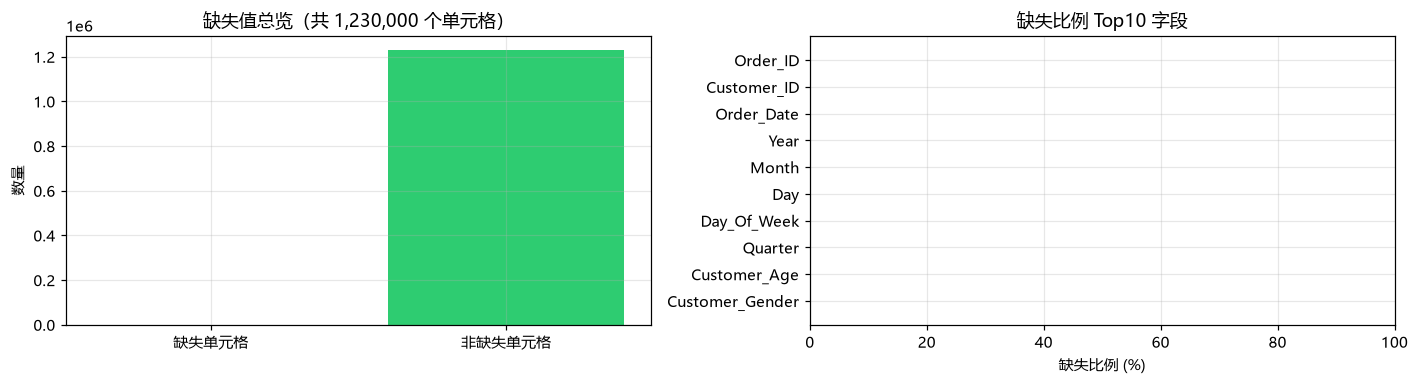

In [11]:
# ---------- ① 缺失值统计表 ----------
missing = pd.DataFrame({
    "缺失数量": df.isna().sum(),
    "缺失比例(%)": (df.isna().mean() * 100).round(2),
})
missing = missing.sort_values("缺失数量", ascending=False)

print("① 缺失值统计（仅显示有缺失的字段）：")
display(missing[missing["缺失数量"] > 0] if missing["缺失数量"].sum() > 0 else pd.DataFrame(columns=["缺失数量", "缺失比例(%)"]))

print(f"全表缺失单元格总数：{int(df.isna().sum().sum())}")
print(f"存在缺失的字段个数：{int((missing['缺失数量'] > 0).sum())} / {df.shape[1]}")

# ---------- ② 整行全空 / 关键字段缺失 ----------
key_cols = ["Order_ID", "Customer_ID", "Product_ID", "Order_Date", "Order_Amount"]
print(f"② 整行全空的记录数：{int(df.isna().all(axis=1).sum())}")
print(f"关键字段缺失的记录数：{int(df[key_cols].isna().any(axis=1).sum())}  （关键字段：{key_cols}）")

# ---------- ③ 缺失情况可视化 ----------
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))

# 左图：全表缺失总览
axes[0].bar(["缺失单元格", "非缺失单元格"],
            [df.isna().sum().sum(), df.size - df.isna().sum().sum()],
            color=["#e74c3c", "#2ecc71"])
axes[0].set_title(f"缺失值总览（共 {df.size:,} 个单元格）")
axes[0].set_ylabel("数量")

# 右图：缺失比例最高的 10 个字段
top_missing = missing.head(10)
axes[1].barh(top_missing.index[::-1], top_missing["缺失比例(%)"][::-1], color="#3498db")
axes[1].set_title("缺失比例 Top10 字段")
axes[1].set_xlabel("缺失比例 (%)")
axes[1].set_xlim(0, 100)

plt.tight_layout()
plt.show()

## 10. 缺失值处理

**实现功能**：编写一个可复用的缺失值处理函数 `handle_missing()`，按字段类型采用不同策略：

| 字段类型 | 处理策略 | 理由 |
| --- | --- | --- |
| ID / 日期 / 关键字段 | 删除该行 | 无法推断，且影响主键与时间分析 |
| 数值型 | 中位数填充（`median`） | 对极端值不敏感，比均值更稳健 |
| 分类型 | 众数填充（`mode`） | 保持类别分布不被破坏 |
| 缺失比例 > 阈值（默认 60%） | 删除整列 | 缺失过多，填充会引入强噪声 |

执行后输出「处理前后缺失数量对比」，并说明本数据集的实际处理结果。

In [12]:
def handle_missing(
    data: pd.DataFrame,
    key_cols: list,
    missing_rate_limit: float = 0.6,
    fill_numeric: str = "median",
) -> tuple:
    """通用缺失值处理函数。

    参数
    ----
    data              : 待处理数据
    key_cols          : 关键字段，缺失则删除所在行
    missing_rate_limit: 缺失比例超过该阈值的字段整列删除
    fill_numeric      : 数值型字段的填充策略，median / mean

    返回
    ----
    (处理后的数据, 处理日志 DataFrame)
    """
    data = data.copy()
    logs = []

    # ① 缺失比例过高的字段：直接删除整列
    high_missing_cols = [
        c for c in data.columns if data[c].isna().mean() > missing_rate_limit
    ]
    if high_missing_cols:
        data = data.drop(columns=high_missing_cols)
        logs.append(f"删除缺失比例 > {missing_rate_limit:.0%} 的字段 {len(high_missing_cols)} 个：{high_missing_cols}")

    # ② 关键字段缺失：删除整行
    before_rows = len(data)
    if key_cols:
        data = data.dropna(subset=[c for c in key_cols if c in data.columns])
    logs.append(f"关键字段缺失删除行数：{before_rows - len(data)}")

    # ③ 按字段类型填充
    numeric_targets = [c for c in data.columns if c in num_cols and c not in key_cols]
    category_targets = [c for c in data.columns if c in cat_cols and c not in key_cols]

    filled_num = 0
    for col in numeric_targets:
        if data[col].isna().any():
            value = data[col].median() if fill_numeric == "median" else data[col].mean()
            filled_num += int(data[col].isna().sum())
            data[col] = data[col].fillna(value)

    filled_cat = 0
    for col in category_targets:
        if data[col].isna().any():
            mode_value = data[col].mode(dropna=True)
            if len(mode_value) > 0:
                filled_cat += int(data[col].isna().sum())
                data[col] = data[col].fillna(mode_value.iloc[0])

    logs.append(f"数值型字段填充缺失值 {filled_num} 个（策略：{fill_numeric}）")
    logs.append(f"分类型字段填充缺失值 {filled_cat} 个（策略：mode 众数）")
    return data, pd.DataFrame({"处理日志": logs})


# ---------- 执行缺失值处理 ----------
missing_before = int(df.isna().sum().sum())
df, missing_log = handle_missing(df, key_cols=key_cols)
missing_after = int(df.isna().sum().sum())

print(f"处理前缺失单元格：{missing_before}")
display(missing_log)
print(f"处理后缺失单元格：{missing_after}  →  {'✅ 数据已无缺失' if missing_after == 0 else '⚠️ 仍有缺失，需人工确认'}")
print(f"当前数据规模：{df.shape[0]:,} 行 × {df.shape[1]} 列")

处理前缺失单元格：0


,处理日志
0,关键字段缺失删除行数：0
1,数值型字段填充缺失值 0 个（策略：median）
2,分类型字段填充缺失值 0 个（策略：mode 众数）


处理后缺失单元格：0  →  ✅ 数据已无缺失
当前数据规模：30,000 行 × 41 列


## 11. 重复值分析

**实现功能**：从三个层次检查重复：
1. **完全重复行**：所有字段取值完全相同 → 属于重复录入，直接删除。
2. **主键重复**：`Order_ID` 重复 → 违反订单唯一性。
3. **业务重复**：同一客户、同一产品、同一天下的同一笔订单（`Customer_ID + Product_ID + Order_Date` 完全一致且金额相同）→ 疑似重复下单。

输出各层次重复数量，并保留第一条、删除多余的重复记录。

In [13]:
rows_before = len(df)

# ---------- ① 完全重复行 ----------
dup_full = int(df.duplicated().sum())

# ---------- ② 主键重复 ----------
dup_pk = int(df.duplicated(subset=["Order_ID"]).sum())

# ---------- ③ 业务重复（客户 + 产品 + 日期 + 金额 都相同） ----------
business_key = ["Customer_ID", "Product_ID", "Order_Date", "Order_Amount"]
dup_business = int(df.duplicated(subset=business_key).sum())

# ---------- ④ 主键唯一性与重复概览 ----------
print("① 完全重复行数：", dup_full)
print("② Order_ID 重复行数：", dup_pk)
print(f"③ 业务键 {business_key} 重复行数：{dup_business}")

print("\n主键唯一性检查：")
print(f"  · Order_ID 唯一值 {df['Order_ID'].nunique():,} / 总行数 {len(df):,} → "
      f"{'✅ 唯一' if df['Order_ID'].is_unique else '❌ 存在重复'}")
print(f"  · Customer_ID 唯一客户数：{df['Customer_ID'].nunique():,}")
print(f"  · Product_ID  唯一产品数：{df['Product_ID'].nunique():,}")

# ---------- ⑤ 去重（保留首条） ----------
df = df.drop_duplicates(subset=["Order_ID"], keep="first").reset_index(drop=True)
df = df.drop_duplicates(keep="first").reset_index(drop=True)

print(f"\n去重结果：{rows_before:,} 行 → {len(df):,} 行，共删除 {rows_before - len(df):,} 行重复记录")

① 完全重复行数： 0
② Order_ID 重复行数： 0
③ 业务键 ['Customer_ID', 'Product_ID', 'Order_Date', 'Order_Amount'] 重复行数：0

主键唯一性检查：
  · Order_ID 唯一值 30,000 / 总行数 30,000 → ✅ 唯一
  · Customer_ID 唯一客户数：8,683
  · Product_ID  唯一产品数：2,500

去重结果：30,000 行 → 30,000 行，共删除 0 行重复记录


## 12. 日期字段合理性校验

**实现功能**：
1. 查看订单日期的**时间跨度**、最早/最晚订单日期、日期是否连续（是否存在整天无订单的缺口）。
2. **交叉校验**：`Order_Date` 衍生的年/月/日/星期/季度，是否与数据集中已有的 `Year / Month / Day / Day_Of_Week / Quarter` 字段一致 —— 用来发现"日期字段与派生字段矛盾"的脏数据。
3. 校验 `Season` 与月份是否匹配（12/1/2 冬季、3-5 春季、6-8 夏季、9-11 秋季）。
4. 绘制按月订单量折线图，直观查看时间序列是否异常。

① 订单日期时间跨度：
   最早订单日期：2023-01-01
   最晚订单日期：2026-12-31
   跨度：1,460 天（4 个年度）
   有订单的日期数：1,461 / 1,461 天 → ✅ 日期连续无缺口

② 日期字段与派生字段一致性：
   · Year       不一致记录数：    0  ✅
   · Month      不一致记录数：    0  ✅
   · Day        不一致记录数：    0  ✅
   · Quarter    不一致记录数：    0  ✅
   · Day_Of_Week 不一致记录数：  0  ✅

③ Season 与月份不匹配记录数：0  ✅


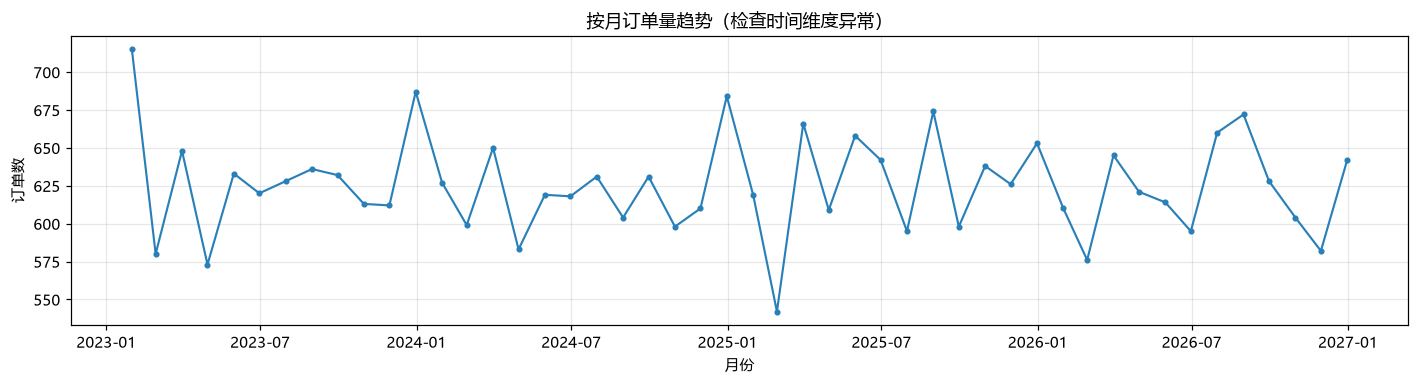

In [ ]:
print("① 订单日期时间跨度：")
print(f"   最早订单日期：{df['Order_Date'].min().date()}")
print(f"   最晚订单日期：{df['Order_Date'].max().date()}")
span_days = (df["Order_Date"].max() - df["Order_Date"].min()).days
print(f"   跨度：{span_days:,} 天（{(df['Order_Date'].dt.year.nunique())} 个年度）")

# 日期连续性：是否存在整天没有订单的缺口
all_days = pd.date_range(df["Order_Date"].min(), df["Order_Date"].max(), freq="D")
missing_days = all_days.difference(df["Order_Date"].unique())
print(f"   有订单的日期数：{df['Order_Date'].nunique():,} / {len(all_days):,} 天 → "
      f"{'✅ 日期连续无缺口' if len(missing_days) == 0 else f'⚠️ 有 {len(missing_days)} 天无订单'}")

# ---------- ② 日期与派生字段交叉校验 ----------
checks = {
    "Year": df["Order_Date"].dt.year,
    "Month": df["Order_Date"].dt.month,
    "Day": df["Order_Date"].dt.day,
    "Quarter": df["Order_Date"].dt.quarter,
}
print("\n② 日期字段与派生字段一致性：")
for col, truth in checks.items():
    mismatch = int((df[col].astype(int) != truth.astype(int)).sum())
    print(f"   · {col:<10} 不一致记录数：{mismatch:>5}  {'✅' if mismatch == 0 else '❌'}")

# 星期：统一用英文全称比较
weekday_mismatch = int((df["Day_Of_Week"].astype("str") != df["Order_Date"].dt.day_name()).sum())
print(f"   · Day_Of_Week 不一致记录数：{weekday_mismatch:>3}  {'✅' if weekday_mismatch == 0 else '❌'}")

# ---------- ③ Season 与月份是否匹配 ----------
month2season = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn",
}
expected_season = df["Order_Date"].dt.month.map(month2season)
season_mismatch = int((df["Season"].astype("str") != expected_season).sum())
print(f"\n③ Season 与月份不匹配记录数：{season_mismatch}  {'✅' if season_mismatch == 0 else '❌'}")
  
# ---------- ④ 按月订单量趋势 ----------
monthly = df.set_index("Order_Date").resample("ME").size()
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.plot(monthly.index, monthly.values, marker="o", ms=3, lw=1.4, color="#2980b9")
ax.set_title("按月订单量趋势（检查时间维度异常）")
ax.set_xlabel("月份")
ax.set_ylabel("订单数")
plt.tight_layout()
plt.show()

## 13. 未来日期（晚于数据截止日）识别与处理

**实现功能**：
1. 以**当前系统日期**为数据截止日，识别 `Order_Date` 晚于截止日的订单（订单不可能发生在未来，属于典型的时间异常值）。
2. 统计未来订单数量、占比，并查看其分布，判断是否为系统性错误（例如整批数据被误造到 2026 年）。
3. 提供开关 `REMOVE_FUTURE_ORDERS`：默认**删除**未来订单，保证"历史订单"数据的真实性；若后续需要完整年度趋势，可改为 `False` 仅做标记。

> 这一步放在日期校验之后、异常值检测之前，避免未来日期干扰"时间趋势"和"按日期聚合"的统计口径。

In [15]:
TODAY = pd.Timestamp.today().normalize()          # 数据截止日 = 今天
REMOVE_FUTURE_ORDERS = True                       # 是否删除未来订单

future_mask = df["Order_Date"] > TODAY
future_df = df.loc[future_mask]

print(f"数据截止日（今天）：{TODAY.date()}")
print(f"未来订单记录数：{len(future_df):,} 条，占全部订单 {len(future_df) / len(df):.2%}")

if len(future_df) > 0:
    print(f"未来订单日期范围：{future_df['Order_Date'].min().date()} ~ {future_df['Order_Date'].max().date()}")
    print("\n未来订单按月份分布：")
    display(future_df["Order_Date"].dt.to_period("M").value_counts().sort_index().to_frame("订单数"))

    # 标记（无论是否删除都保留标记，便于追溯）
    df["Is_Future_Order"] = future_mask.astype("int8")

    if REMOVE_FUTURE_ORDERS:
        rows_before = len(df)
        df = df.loc[~future_mask].reset_index(drop=True)
        print(f"\n已删除未来订单：{rows_before:,} 行 → {len(df):,} 行")
        print(f"删除后的订单日期范围：{df['Order_Date'].min().date()} ~ {df['Order_Date'].max().date()}")
    else:
        print("\n仅标记未删除（REMOVE_FUTURE_ORDERS = False）")
else:
    print("✅ 未发现未来日期异常")

print(f"\n当前数据规模：{df.shape[0]:,} 行 × {df.shape[1]} 列")

数据截止日（今天）：2026-11-10
未来订单记录数：1,047 条，占全部订单 3.49%
未来订单日期范围：2026-11-11 ~ 2026-12-31

未来订单按月份分布：


,订单数
Order_Date,
2026-11,405
2026-12,642



已删除未来订单：30,000 行 → 28,953 行
删除后的订单日期范围：2023-01-01 ~ 2026-11-10

当前数据规模：28,953 行 × 42 列


## 14. 数值型字段异常值检测（IQR 与 3σ 双方法）

**实现功能**：
1. 对每个数值字段，用 **IQR 箱线图法**（$Q1-1.5IQR$ ~ $Q3+1.5IQR$）与 **3σ 法**（$\mu\pm3\sigma$）两种方法检测异常值。
2. 输出每个字段的上下界、异常数量、异常比例，形成异常值清单表。
3. 绘制箱线图，直观展示各金额字段的离群点分布。
4. 计算偏度（skewness）与峰度，判断分布形态 —— 偏度大说明存在"右偏长尾"，这类数据用 IQR 判断比 3σ 更稳健。

① IQR（1.5 倍四分位距）异常值检测结果：


,下界,上界,低端异常数,高端异常数,异常总数,异常比例(%),偏度,峰度
字段,,,,,,,,
Unit_Price,-118.34,277.14,0,3971,3971,13.72,2.73,9.37
Order_Amount,-376.84,849.83,0,3309,3309,11.43,3.92,23.18
Tax_Amount,-31.24,66.12,0,3224,3224,11.14,4.48,31.87
Discount_Amount,-67.20,112.00,0,3148,3148,10.87,6.25,64.46
Customer_Lifetime_Value,"-4,159.94","9,687.13",0,3136,3136,10.83,3.71,16.76
Profit_Amount,-82.06,181.18,0,2685,2685,9.27,4.86,42.42
Review_Rating,2.10,6.10,241,0,241,0.83,-0.62,0.10
Quantity,-1.00,7.00,0,171,171,0.59,0.71,0.51
Shipping_Cost,-6.27,26.50,0,164,164,0.57,0.66,-0.12



② 3σ 法异常值检测结果（Top10）：


,3σ 下界,3σ 上界,异常数,异常比例(%)
字段,,,,
Customer_Lifetime_Value,"-16,015.43","24,757.68",754,2.60
Unit_Price,-391.21,645.25,732,2.53
Order_Amount,"-1,377.10","2,135.88",723,2.50
Tax_Amount,-119.48,177.81,683,2.36
Profit_Amount,-266.99,415.08,646,2.23
Discount_Amount,-293.45,392.21,614,2.12
Quantity,-1.27,7.43,171,0.59
Review_Rating,1.99,6.11,126,0.44
Customer_Age,2.40,70.36,54,0.19



③ 两种方法对比（偏度大的字段 IQR 更敏感，3σ 因受极端值拉高均值而漏检）：


,IQR 异常数,3σ 异常数,差值
字段,,,
Unit_Price,3971,732,3239
Order_Amount,3309,723,2586
Tax_Amount,3224,683,2541
Discount_Amount,3148,614,2534
Customer_Lifetime_Value,3136,754,2382
Profit_Amount,2685,646,2039
Review_Rating,241,126,115
Shipping_Cost,164,50,114
Delivery_Days,91,22,69


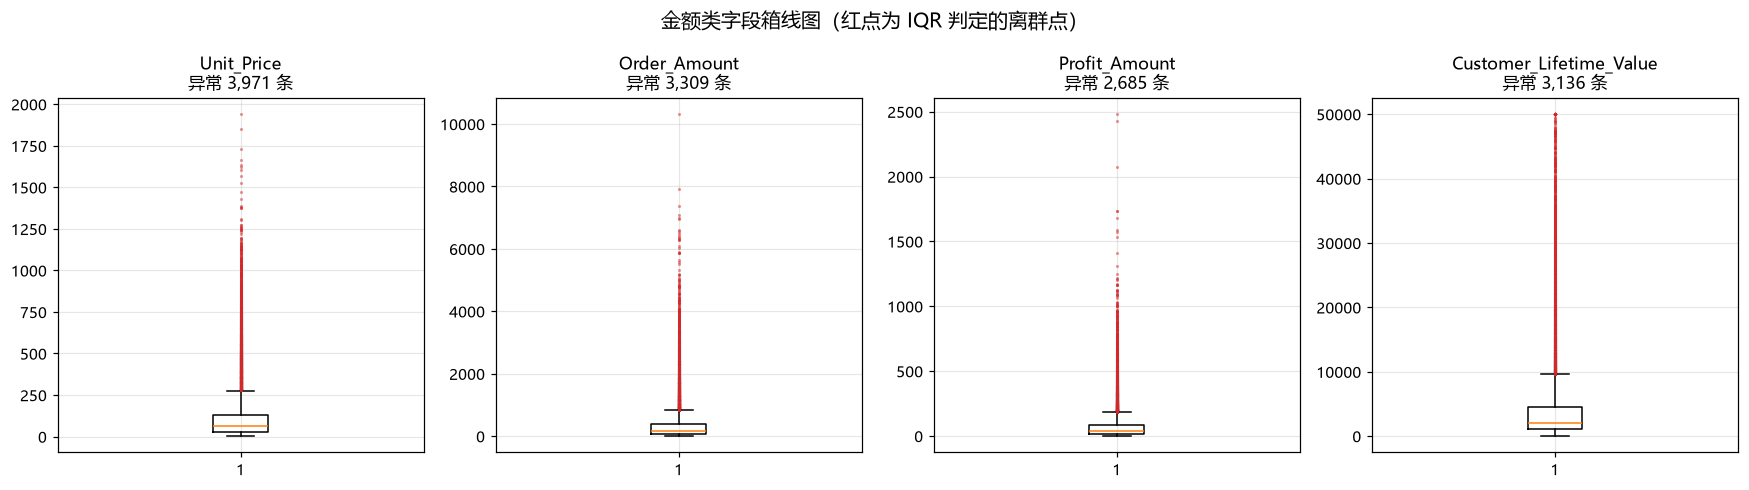

In [18]:
# 只对「有业务含义的连续型字段」做异常值检测（排除 Year/Month/Day/Quarter 等时间编码）
outlier_cols = money_cols + rate_cols + [
    "Customer_Age", "Quantity", "Delivery_Days", "Review_Rating",
]


def outlier_summary_iqr(data, cols, k=1.5):
    """IQR（四分位距）法统计异常值。

    判定规则：正常区间为 [Q1 - k*IQR, Q3 + k*IQR]，落在区间外的记为异常值。
    该方法不依赖正态假设，适合右偏严重的金额类字段。
    """
    rows = []
    for col in cols:
        s = data[col].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        low, high = q1 - k * iqr, q3 + k * iqr
        n_low, n_high = int((s < low).sum()), int((s > high).sum())
        rows.append({
            "字段": col,
            "下界": round(low, 2),
            "上界": round(high, 2),
            "低端异常数": n_low,
            "高端异常数": n_high,
            "异常总数": n_low + n_high,
            "异常比例(%)": round((n_low + n_high) / len(s) * 100, 2),
            "偏度": round(s.skew(), 2),
            "峰度": round(s.kurt(), 2),
        })
    return pd.DataFrame(rows)


iqr_table = outlier_summary_iqr(df, outlier_cols).set_index("字段")
print("① IQR（1.5 倍四分位距）异常值检测结果：")
display(iqr_table.sort_values("异常总数", ascending=False))

# ---------- 3σ 法（正态分布下覆盖 99.73%） ----------
sigma_rows = []
for col in outlier_cols:
    s = df[col].dropna()
    mu, sd = s.mean(), s.std()
    low, high = mu - 3 * sd, mu + 3 * sd
    n_out = int(((s < low) | (s > high)).sum())
    sigma_rows.append({
        "字段": col,
        "3σ 下界": round(low, 2),
        "3σ 上界": round(high, 2),
        "异常数": n_out,
        "异常比例(%)": round(n_out / len(s) * 100, 2),
    })
sigma_table = pd.DataFrame(sigma_rows).set_index("字段")
print("\n② 3σ 法异常值检测结果（Top10）：")
display(sigma_table.sort_values("异常数", ascending=False).head(10))

# ---------- 两种方法对比 ----------
compare_method = iqr_table[["异常总数"]].join(sigma_table[["异常数"]])
compare_method.columns = ["IQR 异常数", "3σ 异常数"]
compare_method["差值"] = compare_method["IQR 异常数"] - compare_method["3σ 异常数"]
print("\n③ 两种方法对比（偏度大的字段 IQR 更敏感，3σ 因受极端值拉高均值而漏检）：")
display(compare_method.sort_values("差值", ascending=False))

# ---------- 箱线图可视化 ----------
plot_cols = ["Unit_Price", "Order_Amount", "Profit_Amount", "Customer_Lifetime_Value"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, col in zip(axes, plot_cols):
    ax.boxplot(df[col].dropna(), flierprops=dict(marker="o", markersize=2,
                markerfacecolor="#d62728", markeredgecolor="none", alpha=0.5))
    ax.set_title(f"{col}\n异常 {iqr_table.loc[col, '异常总数']:,} 条", fontsize=11)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("金额类字段箱线图（红点为 IQR 判定的离群点）", fontsize=13)
plt.tight_layout()
plt.show()

## 15. 分组异常值检测：按商品品类判断价格/金额是否异常

**实现功能**：
1. 不同品类的价格量级差异很大（图书几十元、电子产品上千元），**全表统一用 IQR 会把高档电子产品误判为异常**。因此按 `Product_Category` 分组，在组内用 IQR 检测 `Unit_Price`、`Order_Amount` 的组内异常。
2. 对比「全表异常」与「组内异常」的数量差异，验证上述判断。
3. 标注真正的异常值：`Is_Price_Outlier`（组内异常）、`Is_Amount_Outlier`（组内异常），为后续建模提供筛选依据，**不直接删除**（异常订单本身可能是真实的"高价值订单"，删除会损失业务信息）。

In [19]:
def group_outlier_flag(data: pd.DataFrame, col: str, group: str = "Product_Category", k: float = 1.5) -> pd.Series:
    """在组内用 IQR 判断某列是否为异常值，返回布尔 Series（True 表示异常）。"""
    def _judge(s: pd.Series) -> pd.Series:
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        lower, upper = q1 - k * iqr, q3 + k * iqr
        return (s < lower) | (s > upper)

    return data.groupby(group, observed=True)[col].transform(_judge)


# ---------- ① 生成分组异常标记 ----------
df["Is_Price_Outlier"] = group_outlier_flag(df, "Unit_Price").astype("int8")
df["Is_Amount_Outlier"] = group_outlier_flag(df, "Order_Amount").astype("int8")

# ---------- ② 全表异常 vs 组内异常对比 ----------
compare = pd.DataFrame({
    "全表异常数": [iqr_table.loc["Unit_Price", "异常总数"], iqr_table.loc["Order_Amount", "异常总数"]],
    "组内异常数": [int(df["Is_Price_Outlier"].sum()), int(df["Is_Amount_Outlier"].sum())],
}, index=["Unit_Price", "Order_Amount"])
compare["差异说明"] = compare["全表异常数"] - compare["组内异常数"]
display(compare)

# ---------- ③ 各品类的价格区间与组内异常 ----------
cat_stat = df.groupby("Product_Category", observed=True).agg(
    订单数=("Order_ID", "count"),
    单价中位数=("Unit_Price", "median"),
    单价最大值=("Unit_Price", "max"),
    单价异常数=("Is_Price_Outlier", "sum"),
    金额中位数=("Order_Amount", "median"),
    金额异常数=("Is_Amount_Outlier", "sum"),
).sort_values("单价中位数", ascending=False)
cat_stat["单价异常比例(%)"] = (cat_stat["单价异常数"] / cat_stat["订单数"] * 100).round(2)
print("③ 各品类价格与金额分布：")
display(cat_stat)

print("④ 单价最高的 5 条订单（判断是否为真实高价商品）：")
display(df.nlargest(5, "Unit_Price")[
    ["Order_ID", "Product_Category", "Product_Subcategory", "Unit_Price", "Quantity", "Order_Amount", "Is_Price_Outlier"]
])

print(f"\n异常值处理策略：标记而不删除（价格异常 {int(df['Is_Price_Outlier'].sum()):,} 条，"
      f"金额异常 {int(df['Is_Amount_Outlier'].sum()):,} 条），后续分析/建模可按需过滤。")

,全表异常数,组内异常数,差异说明
Unit_Price,3971,908,3063
Order_Amount,3309,1123,2186


③ 各品类价格与金额分布：


,订单数,单价中位数,单价最大值,单价异常数,金额中位数,金额异常数,单价异常比例(%)
Product_Category,,,,,,,
Electronics,4551,422.93,"1,940.00",144,"1,127.50",185,3.16
Home & Kitchen,4069,129.73,663.85,132,357.41,141,3.24
Sports,2354,79.88,450.69,97,223.25,113,4.12
Fashion,5878,64.23,289.06,196,180.90,238,3.33
Beauty,2851,44.50,164.77,78,130.55,106,2.74
Toys,1987,38.75,147.30,50,116.86,82,2.52
Books,2087,24.71,91.85,51,77.68,76,2.44
Groceries,5176,17.95,71.77,160,57.55,182,3.09


④ 单价最高的 5 条订单（判断是否为真实高价商品）：


,Order_ID,Product_Category,Product_Subcategory,Unit_Price,Quantity,Order_Amount,Is_Price_Outlier
22204,619315,Electronics,Headphones,"1,940.00",3,"5,856.74",1
3088,626524,Electronics,Laptop,"1,853.01",5,"10,314.27",1
11529,628830,Electronics,Mobile,"1,730.25",2,"2,899.08",1
18816,605447,Electronics,Laptop,"1,665.32",6,"7,919.29",1
24042,616207,Electronics,Headphones,"1,634.95",1,"1,168.46",1



异常值处理策略：标记而不删除（价格异常 908 条，金额异常 1,123 条），后续分析/建模可按需过滤。


## 16. 业务逻辑一致性校验

**实现功能**：按业务公式与业务规则反向验证数据，找出「数值上说不通」的记录：

| 校验项 | 业务公式 / 规则 |
| --- | --- |
| 订单金额 | `Order_Amount ≈ Unit_Price × Quantity − Discount_Amount + Tax_Amount + Shipping_Cost` |
| 折扣金额 | `Discount_Amount ≈ Unit_Price × Quantity × Discount_Percent / 100` |
| 利润金额 | `Profit_Amount ≈ Order_Amount × Profit_Margin_Percent / 100` |
| 优惠券与折扣 | `Coupon_Used = Yes` 时应有折扣；有折扣时是否使用优惠券 |
| 订单状态与退货 | `Order_Status = Returned` 记录应满足 `Returned = Yes`，反之亦然 |
| 退货与已取消 | 已取消订单不应产生退货 |
| 目标变量定义 | `High_Value_Order` 是否等于"订单金额 > 75 分位数（388.19）" |

输出各项的「异常记录数」，作为后续修正的依据。

In [21]:
TOL = 0.02   # 金额允许误差（浮点四舍五入导致）

gross = df["Unit_Price"] * df["Quantity"]

# ---------- ① 金额公式：单价 × 数量 - 折扣 + 税 + 运费 ----------
amount_calc = gross - df["Discount_Amount"] + df["Tax_Amount"] + df["Shipping_Cost"]
bad_amount = (df["Order_Amount"] - amount_calc).abs() > TOL

# ---------- ② 折扣公式：折扣额 = 单价 × 数量 × 折扣率 ----------
discount_calc = gross * df["Discount_Percent"] / 100
bad_discount = (df["Discount_Amount"] - discount_calc).abs() > TOL

# ---------- ③ 利润公式：利润额 = 订单金额 × 利润率 ----------
profit_calc = df["Order_Amount"] * df["Profit_Margin_Percent"] / 100
bad_profit = (df["Profit_Amount"] - profit_calc).abs() > TOL

# ---------- ④ 优惠券与折扣的语义一致性 ----------
coupon_yes_no_discount = (df["Coupon_Used"].astype("str") == "Yes") & (df["Discount_Percent"] == 0)
coupon_no_but_discount = (df["Coupon_Used"].astype("str") == "No") & (df["Discount_Percent"] > 0)

# ---------- ⑤ 订单状态 与 退货标记 ----------
status_ret = df["Order_Status"].astype("str")
status_is_returned = status_ret == "Returned"
returned_flag = df["Returned"].astype("str") == "Yes"
bad_return_1 = status_is_returned & ~returned_flag          # 状态为退货但标记为未退货
bad_return_2 = ~status_is_returned & returned_flag          # 状态非退货但标记为已退货
cancelled_returned = (status_ret == "Cancelled") & returned_flag

# ---------- ⑥ 目标变量定义：High_Value_Order 是否等于「金额 > 75 分位」 ----------
hv_threshold = df["Order_Amount"].quantile(0.75)
hv_from_amount = df["Order_Amount"] > hv_threshold
hv_flag = df["High_Value_Order"].astype("str") == "Yes"
bad_hv = hv_from_amount != hv_flag

# ---------- 汇总 ----------
logic_report = pd.DataFrame({
    "校验项": [
        "订单金额公式", "折扣金额公式", "利润金额公式",
        "使用优惠券但折扣率=0", "未使用优惠券但有折扣",
        "状态=Returned 但 Returned=No", "Returned=Yes 但状态≠Returned", "已取消却标记退货",
        "High_Value_Order 与金额分位数不一致",
    ],
    "异常记录数": [
        int(bad_amount.sum()), int(bad_discount.sum()), int(bad_profit.sum()),
        int(coupon_yes_no_discount.sum()), int(coupon_no_but_discount.sum()),
        int(bad_return_1.sum()), int(bad_return_2.sum()), int(cancelled_returned.sum()),
        int(bad_hv.sum()),
    ],
}).set_index("校验项")
logic_report["异常比例(%)"] = (logic_report["异常记录数"] / len(df) * 100).round(3)

# 针对「有差异但业务上可解释」的项给出判断，避免只看数量误判为脏数据
conclusion_notes = {
    "使用优惠券但折扣率=0": "💡 可解释：券可能为免运费券/赠品券，不减商品价",
    "未使用优惠券但有折扣": "💡 可解释：促销活动折扣，无需用券",
    "High_Value_Order 与金额分位数不一致": "⚠️ 标签口径有偏差，已另建 High_Value_Order_Calc 对照列",
}
logic_report["结论"] = [
    "✅ 通过" if n == 0 else conclusion_notes.get(name, "⚠️ 需处理/关注")
    for name, n in zip(logic_report.index, logic_report["异常记录数"])
]
display(logic_report)

print(f"目标变量阈值验证：Order_Amount 的 75 分位数 = {hv_threshold:,.2f}")
print("订单状态 × 退货标记 交叉表：")
display(pd.crosstab(df["Order_Status"], df["Returned"]))

,异常记录数,异常比例(%),结论
校验项,,,
订单金额公式,0,0.00,✅ 通过
折扣金额公式,0,0.00,✅ 通过
利润金额公式,0,0.00,✅ 通过
使用优惠券但折扣率=0,1387,4.79,💡 可解释：券可能为免运费券/赠品券，不减商品价
未使用优惠券但有折扣,2997,10.35,💡 可解释：促销活动折扣，无需用券
状态=Returned 但 Returned=No,0,0.00,✅ 通过
Returned=Yes 但状态≠Returned,0,0.00,✅ 通过
已取消却标记退货,0,0.00,✅ 通过
High_Value_Order 与金额分位数不一致,30,0.10,⚠️ 标签口径有偏差，已另建 High_Value_Order_Calc 对照列


目标变量阈值验证：Order_Amount 的 75 分位数 = 389.83
订单状态 × 退货标记 交叉表：


Returned,No,Yes
Order_Status,,
Cancelled,1695,0
Delivered,18829,0
Processing,2158,0
Returned,0,2924
Shipped,3347,0


## 17. 业务逻辑异常的处理

**实现功能**：上一节发现的逻辑问题，按"可确定 → 修正，不确定 → 标记"的原则处理：

| 逻辑问题 | 处理方式 |
| --- | --- |
| 已取消（Cancelled）订单却有配送天数 | 置为缺失（订单未履约，无配送时长），避免拉低平均配送时长 |
| 已取消（Cancelled）订单却有评分 | 置为缺失（未收到货无法评价） |
| 配送方式 ≠ Same Day 但配送天数为 0 | 新增 `Is_Delivery_Days_Suspect` 标记（可能是当日达/录入错误，无法确定，故不删除） |
| 使用优惠券但折扣率为 0 | 保留原值，仅统计（可能为免运费券/满减券，不能直接判为错误） |
| `High_Value_Order` 与金额分位数不一致 | 以现有 `High_Value_Order` 标签为准（目标变量），并保留 `High_Value_Order_Calc` 备查 |

处理完成后输出「修正前后」的对比，确认修改范围可控。

In [23]:
status_str = df["Order_Status"].astype("str")
is_cancelled = status_str == "Cancelled"
not_same_day = df["Shipping_Method"].astype("str") != "Same Day"

# ---------- ① 修正前快照 ----------
before_snapshot = pd.DataFrame({
    "已取消订单数": [int(is_cancelled.sum())],
    "已取消但有配送天数": [int((is_cancelled & (df["Delivery_Days"] > 0)).sum())],
    "已取消但有评分": [int((is_cancelled & df["Review_Rating"].notna()).sum())],
    "非当日达但配送天数=0": [int((not_same_day & (df["Delivery_Days"] == 0)).sum())],
})
print("① 修正前：")
display(before_snapshot)

# ---------- ② 已取消订单：配送天数 / 评分置为缺失（业务上不应存在） ----------
df["Delivery_Days"] = df["Delivery_Days"].astype("float64")
df.loc[is_cancelled, "Delivery_Days"] = np.nan
df.loc[is_cancelled, "Review_Rating"] = np.nan

# ---------- ③ 配送天数可疑标记（不删除，仅打标记） ----------
df["Is_Delivery_Days_Suspect"] = (not_same_day & (df["Delivery_Days"] == 0)).astype("int8")

# ---------- ④ 目标变量：保留原始标签，并生成按分位数计算的对照列 ----------
df["High_Value_Order_Calc"] = (df["Order_Amount"] > hv_threshold).astype("int8")

# ---------- ⑤ 修正后核对 ----------
after_snapshot = pd.DataFrame({
    "已取消订单数": [int(is_cancelled.sum())],
    "已取消且配送天数缺失": [int(df.loc[is_cancelled, "Delivery_Days"].isna().sum())],
    "已取消且评分缺失": [int(df.loc[is_cancelled, "Review_Rating"].isna().sum())],
    "配送天数可疑标记数": [int(df["Is_Delivery_Days_Suspect"].sum())],
})
print("② 修正后：")
display(after_snapshot)

print("③ 修正后各订单状态的配送天数 / 评分情况：")
display(df.groupby("Order_Status", observed=True).agg(
    订单数=("Order_ID", "count"),
    配送天数非空数=("Delivery_Days", "count"),
    平均配送天数=("Delivery_Days", "mean"),
    评分数=("Review_Rating", "count"),
    平均评分=("Review_Rating", "mean"),
).round(2))

print(f"④ 目标变量一致性：High_Value_Order 与 High_Value_Order_Calc 不一致 "
      f"{int((df['High_Value_Order'].astype('str') != np.where(df['High_Value_Order_Calc'] == 1, 'Yes', 'No')).sum())} 条")

# ---------- ⑥ 附加发现：未完成订单却已有配送/评分信息 ----------
unfinished = status_str.isin(["Processing", "Shipped"])
unfinished_has_logistics = unfinished & df["Delivery_Days"].notna()
unfinished_has_rating = unfinished & df["Review_Rating"].notna()
print(f"⑤ 附加发现：未完成订单（Processing/Shipped）共 {int(unfinished.sum()):,} 条，"
      f"其中已有配送天数 {int(unfinished_has_logistics.sum()):,} 条、已有评分 {int(unfinished_has_rating.sum()):,} 条。")
print("   说明：该现象源于模拟数据的生成方式，无法判定为错误，暂不删除，仅在此记录，"
      "后续分析配送时效/评分时建议只使用 Order_Status = Delivered 的子集。")

① 修正前：


,已取消订单数,已取消但有配送天数,已取消但有评分,非当日达但配送天数=0
0,1695,0,0,773


② 修正后：


,已取消订单数,已取消且配送天数缺失,已取消且评分缺失,配送天数可疑标记数
0,1695,1695,1695,773


③ 修正后各订单状态的配送天数 / 评分情况：


,订单数,配送天数非空数,平均配送天数,评分数,平均评分
Order_Status,,,,,
Cancelled,1695,0,NaN,0,NaN
Delivered,18829,18829,4.43,18829,4.16
Processing,2158,2158,4.44,2158,4.17
Returned,2924,2924,4.45,2924,3.08
Shipped,3347,3347,4.47,3347,4.15


④ 目标变量一致性：High_Value_Order 与 High_Value_Order_Calc 不一致 30 条
⑤ 附加发现：未完成订单（Processing/Shipped）共 5,505 条，其中已有配送天数 5,505 条、已有评分 5,505 条。
   说明：该现象源于模拟数据的生成方式，无法判定为错误，暂不删除，仅在此记录，后续分析配送时效/评分时建议只使用 Order_Status = Delivered 的子集。


## 18. 实体一致性检查（客户 / 产品 / 城市-国家映射）

**实现功能**：检查"同一个实体在不同订单中的属性是否一致"，这是订单表中很常见的**隐蔽脏数据**：

1. **客户维度**：同一个 `Customer_ID` 的 `Customer_Age / Customer_Gender / Country / City / Customer_Segment` 是否始终一致。
2. **产品维度**：同一个 `Product_ID` 的 `Product_Category / Subcategory / Brand / Unit_Price` 是否始终一致。
3. **地理维度**：`City` 与 `Country` 是否为固定映射（一个城市是否只属于一个国家）。

输出每种实体的"属性冲突比例"，并据此给出后续分析的使用建议（这一步只做诊断和记录，不删除数据，避免误删真实订单）。

In [24]:
def entity_consistency_report(data: pd.DataFrame, entity: str, attrs: list) -> pd.DataFrame:
    """检查同一实体在多个订单中属性是否唯一，返回冲突统计表。"""
    nunique = data.groupby(entity, observed=True)[attrs].nunique()
    total = len(nunique)
    rows = []
    for col in attrs:
        conflict = int((nunique[col] > 1).sum())
        rows.append({
            "属性": col,
            "唯一值>1的实体数": conflict,
            "冲突比例(%)": round(conflict / total * 100, 2),
        })
    result = pd.DataFrame(rows).set_index("属性")
    result["实体总数"] = total
    return result


# ---------- ① 客户维度 ----------
cust_attrs = ["Customer_Age", "Customer_Gender", "Country", "City", "Customer_Segment"]
print("① 客户实体一致性（同一 Customer_ID 的属性是否唯一）：")
display(entity_consistency_report(df, "Customer_ID", cust_attrs))

# ---------- ② 产品维度 ----------
prod_attrs = ["Product_Category", "Product_Subcategory", "Brand", "Unit_Price"]
print("② 产品实体一致性（同一 Product_ID 的属性是否唯一）：")
display(entity_consistency_report(df, "Product_ID", prod_attrs))

# ---------- ③ 城市-国家映射 ----------
city_country = df.groupby("City", observed=True)["Country"].nunique().sort_values(ascending=False)
print("③ 城市-国家映射（一个城市对应的国家数）：")
display(city_country.to_frame("对应国家数"))
print(f"   城市数：{df['City'].nunique()}，国家数：{df['Country'].nunique()}；"
      f"城市-国家为一对一的个数：{(city_country == 1).sum()}")

# ---------- ④ 结论 ----------
print("\n④ 诊断结论：")
print("   · Customer_ID 的年龄/性别/国家/城市/分层在不同订单中大量不一致 → 不能把 Customer_ID 当作稳定的客户画像键")
print("   · Product_ID 的品类/品牌/单价在不同订单中不一致 → Product_ID 不携带固定的商品属性")
print("   · City 与 Country 不是一对一映射 → 不能据此做地理层级汇总")
print("   处理方式：不删除记录（删除会损失大量真实订单），而是在后续分析中把上述字段当作「订单级属性」使用。")

① 客户实体一致性（同一 Customer_ID 的属性是否唯一）：


,唯一值>1的实体数,冲突比例(%),实体总数
属性,,,
Customer_Age,7440,86.10,8641
Customer_Gender,5824,67.40,8641
Country,7257,83.98,8641
City,7297,84.45,8641
Customer_Segment,6710,77.65,8641


② 产品实体一致性（同一 Product_ID 的属性是否唯一）：


,唯一值>1的实体数,冲突比例(%),实体总数
属性,,,
Product_Category,2500,100.00,2500
Product_Subcategory,2500,100.00,2500
Brand,2500,100.00,2500
Unit_Price,2500,100.00,2500


③ 城市-国家映射（一个城市对应的国家数）：


,对应国家数
City,
Berlin,10
Dubai,10
Karachi,10
London,10
Mumbai,10
New York,10
Paris,10
Riyadh,10
Sydney,10


   城市数：10，国家数：10；城市-国家为一对一的个数：0

④ 诊断结论：
   · Customer_ID 的年龄/性别/国家/城市/分层在不同订单中大量不一致 → 不能把 Customer_ID 当作稳定的客户画像键
   · Product_ID 的品类/品牌/单价在不同订单中不一致 → Product_ID 不携带固定的商品属性
   · City 与 Country 不是一对一映射 → 不能据此做地理层级汇总
   处理方式：不删除记录（删除会损失大量真实订单），而是在后续分析中把上述字段当作「订单级属性」使用。


## 19. 极端值的温和处理：分位数截尾（Winsorize）

**实现功能**：异常值已在前面的步骤中**标记**，但对金额类字段做统计/建模时，少数极端值仍会严重拉偏均值与方差。因此提供一套"温和"的处理方案：

1. 对 `Order_Amount / Profit_Amount / Customer_Lifetime_Value` 按 **1% 与 99% 分位数截尾**，生成 `*_Winsor` 列（原列保持不变）。
2. 对比截尾前后的 `mean / std / min / max`，量化截尾效果。
3. 检查 `Customer_Lifetime_Value` 的**封顶现象**（最大值 50,000，存在多条记录等于该值），判断是否为人为截断。

> 保留原始列 + 新增截尾列，是为了让后续分析可以自由选择：描述性分析用原始值，建模/对比用截尾值。

① 截尾前统计：


,mean,std,min,max
Order_Amount,379.39,585.50,6.67,"10,314.27"
Profit_Amount,74.04,113.68,0.27,"2,480.54"
Customer_Lifetime_Value,"4,371.13","6,795.52",20.00,"50,000.00"


② 截尾后统计：


,mean,std,min,max
Order_Amount,370.07,525.50,20.56,"2,906.22"
Profit_Amount,71.95,98.41,2.28,581.95
Customer_Lifetime_Value,"4,282.63","6,276.39",20.00,"37,091.79"


③ Customer_Lifetime_Value 最大值：50,000，等于最大值的记录数：130 条 （占比 0.45%）→ 存在人为封顶（截断）现象，分析时需注意


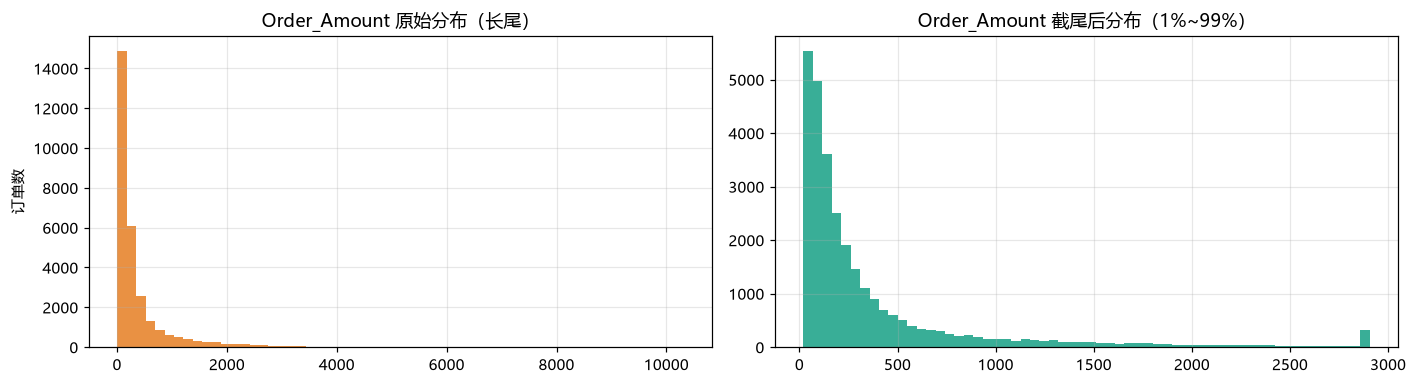

In [25]:
def winsorize(s: pd.Series, lower_q: float = 0.01, upper_q: float = 0.99) -> pd.Series:
    """按分位数对序列做截尾处理（超出上下分位数的值替换为分位数本身）。"""
    lower, upper = s.quantile(lower_q), s.quantile(upper_q)
    return s.clip(lower=lower, upper=upper)


winsor_cols = ["Order_Amount", "Profit_Amount", "Customer_Lifetime_Value"]
for col in winsor_cols:
    df[f"{col}_Winsor"] = winsorize(df[col])

# ---------- ① 截尾前后统计对比 ----------
before = df[winsor_cols].agg(["mean", "std", "min", "max"]).T
after = df[[f"{c}_Winsor" for c in winsor_cols]].agg(["mean", "std", "min", "max"]).T
after.index = winsor_cols

print("① 截尾前统计：")
display(before.round(2))
print("② 截尾后统计：")
display(after.round(2))

# ---------- ③ CLV 封顶检查 ----------
clv_max = df["Customer_Lifetime_Value"].max()
clv_capped = int((df["Customer_Lifetime_Value"] == clv_max).sum())
print(f"③ Customer_Lifetime_Value 最大值：{clv_max:,.0f}，等于最大值的记录数：{clv_capped} 条 "
      f"（占比 {clv_capped / len(df):.2%}）→ 存在人为封顶（截断）现象，分析时需注意")

# ---------- ④ 截尾效果可视化 ----------
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].hist(df["Order_Amount"], bins=60, color="#e67e22", alpha=0.85)
axes[0].set_title("Order_Amount 原始分布（长尾）")
axes[0].set_ylabel("订单数")
axes[1].hist(df["Order_Amount_Winsor"], bins=60, color="#16a085", alpha=0.85)
axes[1].set_title("Order_Amount 截尾后分布（1%~99%）")
plt.tight_layout()
plt.show()

## 20. 二值字段编码（Yes / No → 0 / 1）

**实现功能**：
1. 将 `Coupon_Used / Returned / Holiday_Season / High_Value_Order` 四个 Yes/No 字段转换为 **0/1 整型**，方便后续计算比率（如退货率 = `Returned.mean()`）、做相关性分析和机器学习建模。
2. 采用**新增列**（`*_Flag`）的方式，保留原始文本列，便于对照检查与报告展示。
3. 校验转换前后的分布计数是否一致（No 的数量 = 0 的数量，Yes 的数量 = 1 的数量）。

In [26]:
yes_no_map = {"Yes": 1, "No": 0}

for col in binary_cols:
    flag_col = f"{col}_Flag"
    df[flag_col] = df[col].astype("str").map(yes_no_map).astype("Int8")
    n_yes = int((df[col].astype("str") == "Yes").sum())
    n_flag_1 = int((df[flag_col] == 1).sum())
    n_null = int(df[flag_col].isna().sum())
    status = "✅" if (n_yes == n_flag_1 and n_null == 0) else "❌"
    print(f"{col:<20} Yes={n_yes:>6} → Flag=1: {n_flag_1:>6}，空值 {n_null}  {status}")

print("\n编码后各标记字段的均值（即 Yes 占比）：")
flag_cols = [f"{c}_Flag" for c in binary_cols]
display(df[flag_cols].mean().mul(100).round(2).to_frame("Yes 占比(%)").T)

print("\n抽样查看编码结果：")
df[["Order_ID", "Coupon_Used", "Coupon_Used_Flag", "Returned", "Returned_Flag",
    "Holiday_Season", "Holiday_Season_Flag", "High_Value_Order", "High_Value_Order_Flag"]].head()

Coupon_Used          Yes= 19707 → Flag=1:  19707，空值 0  ✅
Returned             Yes=  2924 → Flag=1:   2924，空值 0  ✅
Holiday_Season       Yes=  3865 → Flag=1:   3865，空值 0  ✅
High_Value_Order     Yes=  7268 → Flag=1:   7268，空值 0  ✅

编码后各标记字段的均值（即 Yes 占比）：


,Coupon_Used_Flag,Returned_Flag,Holiday_Season_Flag,High_Value_Order_Flag
Yes 占比(%),68.07,10.10,13.35,25.10



抽样查看编码结果：


,Order_ID,Coupon_Used,Coupon_Used_Flag,Returned,Returned_Flag,Holiday_Season,Holiday_Season_Flag,High_Value_Order,High_Value_Order_Flag
0,615717,Yes,1,No,0,No,0,No,0
1,626919,Yes,1,No,0,No,0,No,0
2,615781,Yes,1,No,0,No,0,No,0
3,621747,No,0,Yes,1,No,0,No,0
4,625881,Yes,1,No,0,No,0,No,0


## 21. 衍生特征构造

**实现功能**：在不改变原始字段含义的前提下，补充后续分析常用的派生字段：

| 新字段 | 计算方式 | 用途 |
| --- | --- | --- |
| `Gross_Amount` | `Unit_Price × Quantity` | 折前商品金额 |
| `Net_Item_Amount` | `Gross_Amount − Discount_Amount` | 商品实付金额（不含运费税费） |
| `Actual_Discount_Rate(%)` | `Discount_Amount / Gross_Amount × 100` | 实际折扣率，用于校验 `Discount_Percent` |
| `Amount_Per_Item` | `Order_Amount / Quantity` | 单件综合成本，可识别高价订单 |
| `Order_YearMonth` | `Order_Date` 转年月 | 月度趋势分析 |
| `Is_Weekend` | `Day_Of_Week` 是否为周六/周日 | 周末效应分析 |
| `Age_Group` | 年龄分箱（<25, 25-34, 35-44, 45-54, 55+） | 客群分层分析 |
| `Price_Level` | 单价按品类内分位数分为 低价/中价/高价 | 价格带分析 |

同时校验 `Actual_Discount_Rate` 与原始 `Discount_Percent` 是否一致，确保派生逻辑正确。

In [28]:
# ---------- ① 金额类派生字段 ----------
df["Gross_Amount"] = (df["Unit_Price"] * df["Quantity"]).round(2)          # 折前总额
df["Net_Item_Amount"] = (df["Gross_Amount"] - df["Discount_Amount"]).round(2)  # 折后商品额
df["Actual_Discount_Rate(%)"] = np.where(
    df["Gross_Amount"] > 0, df["Discount_Amount"] / df["Gross_Amount"] * 100, 0
).round(2)                                                                 # 实际折扣率
df["Amount_Per_Item"] = (df["Order_Amount"] / df["Quantity"]).round(2)     # 单件实付

# ---------- ② 时间类派生字段 ----------
df["Order_YearMonth"] = df["Order_Date"].dt.to_period("M").astype("str")
df["Is_Weekend"] = df["Day_Of_Week"].astype("str").isin(["Saturday", "Sunday"]).astype("int8")

# ---------- ③ 客群类派生字段：年龄分组 ----------
df["Age_Group"] = pd.cut(
    df["Customer_Age"],
    bins=[0, 24, 34, 44, 54, 200],
    labels=["<25", "25-34", "35-44", "45-54", "55+"],
    include_lowest=True,
)

# ---------- ④ 价格带（按品类内三分位划分，避免不同品类量级差异） ----------
df["Price_Level"] = "中价"
low_thr = df.groupby("Product_Category", observed=True)["Unit_Price"].transform(lambda s: s.quantile(1 / 3))
high_thr = df.groupby("Product_Category", observed=True)["Unit_Price"].transform(lambda s: s.quantile(2 / 3))
df.loc[df["Unit_Price"] < low_thr, "Price_Level"] = "低价"
df.loc[df["Unit_Price"] > high_thr, "Price_Level"] = "高价"

# ---------- ⑤ 校验派生逻辑 ----------
# Discount_Amount 保留 2 位小数，反算折扣率会有细微舍入误差，容差取 0.1 个百分点
rate_diff = (df["Actual_Discount_Rate(%)"] - df["Discount_Percent"]).abs()
print(f"① 实际折扣率与 Discount_Percent 的最大偏差：{rate_diff.max():.4f} 个百分点 → "
      f"{'✅ 派生逻辑正确（差异仅来自金额保留两位小数）' if rate_diff.max() < 0.1 else '⚠️ 存在偏差'}")

new_cols = ["Gross_Amount", "Net_Item_Amount", "Actual_Discount_Rate(%)", "Amount_Per_Item",
            "Order_YearMonth", "Is_Weekend", "Age_Group", "Price_Level"]
print("\n② 新增字段一览：")
print(new_cols)

print("\n③ 派生字段效果示例：")
display(df[["Order_ID", "Unit_Price", "Quantity", "Discount_Amount",
            "Order_Amount"] + new_cols[:4]].head())

print("\n④ 客群分布：")
for col, order in [
    ("Age_Group", ["<25", "25-34", "35-44", "45-54", "55+"]),
    ("Price_Level", ["低价", "中价", "高价"]),
    ("Is_Weekend", [0, 1]),
]:
    vc = df[col].value_counts().reindex(order).rename("订单数").to_frame()
    vc["占比(%)"] = (vc["订单数"] / len(df) * 100).round(2)
    vc.index.name = col
    display(vc)

① 实际折扣率与 Discount_Percent 的最大偏差：0.0700 个百分点 → ✅ 派生逻辑正确（差异仅来自金额保留两位小数）

② 新增字段一览：
['Gross_Amount', 'Net_Item_Amount', 'Actual_Discount_Rate(%)', 'Amount_Per_Item', 'Order_YearMonth', 'Is_Weekend', 'Age_Group', 'Price_Level']

③ 派生字段效果示例：


,Order_ID,Unit_Price,Quantity,Discount_Amount,Order_Amount,Gross_Amount,Net_Item_Amount,Actual_Discount_Rate(%),Amount_Per_Item
0,615717,18.44,3,5.53,68.20,55.32,49.79,10.00,22.73
1,626919,46.58,1,18.63,38.73,46.58,27.95,40.00,38.73
2,615781,62.18,3,65.29,153.66,186.54,121.25,35.00,51.22
3,621747,91.06,3,0.00,298.37,273.18,273.18,0.00,99.46
4,625881,99.44,1,14.92,105.75,99.44,84.52,15.00,105.75



④ 客群分布：


,订单数,占比(%)
Age_Group,,
<25,4839,16.71
25-34,8143,28.12
35-44,9014,31.13
45-54,5158,17.82
55+,1799,6.21


,订单数,占比(%)
Price_Level,,
低价,9648,33.32
中价,9656,33.35
高价,9649,33.33


,订单数,占比(%)
Is_Weekend,,
0,20674,71.41
1,8279,28.59


## 22. 清洗结果总览（清洗前后对比）

**实现功能**：
1. 对比清洗前后 `df_raw` 与 `df` 的**行数、列数、字段数、内存占用**。
2. 汇总本次清洗的**全部动作及影响记录数**（删除未来订单、去重、缺失填充、逻辑修正、新增标记列等）。
3. 复核最终数据是否满足清洗目标：无重复主键、无逻辑冲突、异常值已标记、字段类型正确。
4. 输出最终字段类型清单，作为后续分析的"数据契约"。

In [29]:
# ---------- ① 清洗前后规模对比 ----------
compare_shape = pd.DataFrame({
    "清洗前(df_raw)": [df_raw.shape[0], df_raw.shape[1], df_raw.memory_usage(deep=True).sum() / 1024**2],
    "清洗后(df)": [df.shape[0], df.shape[1], df.memory_usage(deep=True).sum() / 1024**2],
}, index=["行数", "列数", "内存占用(MB)"])
compare_shape["变化"] = compare_shape["清洗后(df)"] - compare_shape["清洗前(df_raw)"]
print("① 清洗前后对比：")
display(compare_shape.round(2))

# ---------- ② 清洗动作清单 ----------
marker_cols = [
    "Is_Future_Order", "Is_Price_Outlier", "Is_Amount_Outlier",
    "Is_Delivery_Days_Suspect", "High_Value_Order_Calc",
]
raw_future = int((pd.to_datetime(df_raw["Order_Date"], errors="coerce") > TODAY).sum())

actions = pd.DataFrame({
    "清洗动作": [
        "删除未来日期订单（晚于今天）",
        "删除完全重复行",
        "删除 Order_ID 重复行",
        "原始缺失单元格数（无需填充）",
        "已取消订单：配送天数置缺失",
        "已取消订单：评分置缺失",
        "新增异常标记字段（个）",
        "新增衍生特征字段（个）",
        "新增截尾字段（个）",
        "最终仍存在的缺失单元格（业务性缺失）",
    ],
    "影响记录数": [
        raw_future,
        int(df_raw.duplicated().sum()),
        int(df_raw.duplicated(subset=["Order_ID"]).sum()),
        int(df_raw.isna().sum().sum()),
        int(is_cancelled.sum()),
        int(is_cancelled.sum()),
        len(marker_cols),
        len(new_cols),
        len(winsor_cols),
        int(df.isna().sum().sum()),
    ],
})
print("② 清洗动作清单：")
display(actions)

# ---------- ③ 最终质量复核 ----------
amount_ok = (
    (df["Order_Amount"] - (df["Gross_Amount"] - df["Discount_Amount"] + df["Tax_Amount"] + df["Shipping_Cost"])).abs() <= TOL
).all()

final_checks = pd.DataFrame({
    "检查项": [
        "Order_ID 唯一", "完全重复行", "未来日期订单", "订单金额公式冲突",
        "状态与退货标记冲突", "数值范围合理（单价/数量/金额 > 0）", "仍存在的缺失单元格",
    ],
    "结果": [
        "✅ 唯一" if df["Order_ID"].is_unique else "❌ 存在重复",
        f"✅ {int(df.duplicated().sum())} 条" if df.duplicated().sum() == 0 else f"❌ {int(df.duplicated().sum())} 条",
        "✅ 无" if (df["Order_Date"] <= TODAY).all() else "❌ 存在",
        "✅ 无冲突" if amount_ok else "❌ 存在冲突",
        "✅ 无冲突" if ((df["Order_Status"].astype("str") == "Returned") == (df["Returned"].astype("str") == "Yes")).all() else "❌ 存在冲突",
        "✅ 全部为正" if (df[["Unit_Price", "Quantity", "Order_Amount"]] > 0).all().all() else "❌ 存在非正值",
        f"⚠️ {int(df.isna().sum().sum())} 个（已取消订单的配送天数与评分，业务性缺失，保留）",
    ],
})
print("③ 最终质量复核：")
display(final_checks)

# ---------- ④ 最终字段类型清单 ----------
print("④ 最终字段类型清单：")
display(pd.DataFrame({
    "数据类型": df.dtypes.astype(str),
    "非空数": df.notna().sum(),
    "唯一值数": df.nunique(),
}))
print(f"\n最终数据规模：{df.shape[0]:,} 行 × {df.shape[1]} 列")

① 清洗前后对比：


,清洗前(df_raw),清洗后(df),变化
行数,"30,000.00","28,953.00","-1,047.00"
列数,41.00,61.00,20.00
内存占用(MB),40.79,12.43,-28.36


② 清洗动作清单：


,清洗动作,影响记录数
0,删除未来日期订单（晚于今天）,1047
1,删除完全重复行,0
2,删除 Order_ID 重复行,0
3,原始缺失单元格数（无需填充）,0
4,已取消订单：配送天数置缺失,1695
5,已取消订单：评分置缺失,1695
6,新增异常标记字段（个）,5
7,新增衍生特征字段（个）,8
8,新增截尾字段（个）,3
9,最终仍存在的缺失单元格（业务性缺失）,3390


③ 最终质量复核：


,检查项,结果
0,Order_ID 唯一,✅ 唯一
1,完全重复行,✅ 0 条
2,未来日期订单,✅ 无
3,订单金额公式冲突,✅ 无冲突
4,状态与退货标记冲突,✅ 无冲突
5,数值范围合理（单价/数量/金额 > 0）,✅ 全部为正
6,仍存在的缺失单元格,⚠️ 3390 个（已取消订单的配送天数与评分，业务性缺失，保留）


④ 最终字段类型清单：


,数据类型,非空数,唯一值数
Order_ID,int64,28953,28953
Customer_ID,str,28953,8641
Order_Date,datetime64[us],28953,1410
Year,int16,28953,4
Month,int16,28953,12
...,...,...,...
Amount_Per_Item,float64,28953,15676
Order_YearMonth,str,28953,47
Is_Weekend,int8,28953,2
Age_Group,category,28953,5



最终数据规模：28,953 行 × 61 列


## 23. 保存清洗后的数据

**实现功能**：
1. 将清洗后的数据保存为 `ecommerce_orders_cleaned.csv`（`index=False`，UTF-8 编码），供后续分析 Notebook 直接读取，避免重复清洗。
2. 同时导出一份**清洗日志** `cleaning_log.csv`，记录每一步的清洗动作与影响数量，便于写分析报告时引用。
3. 重新读取保存的文件，校验列数、行数是否一致，确保落盘成功。

In [30]:
OUTPUT_PATH = ROOT / "data" / "ecommerce_orders_cleaned.csv"
LOG_PATH = ROOT / "data" / "cleaning_log.csv"

# 去除 category 类型不便保存的问题：直接 to_csv 即可（category 会写成文本）
df.to_csv(OUTPUT_PATH, index=False, encoding="utf-8-sig")
actions.to_csv(LOG_PATH, index=False, encoding="utf-8-sig")

# 回读校验
df_check = pd.read_csv(OUTPUT_PATH)
print(f"① 已保存：{OUTPUT_PATH.relative_to(ROOT)}")
print(f"   行数：{df.shape[0]:,} → 回读 {len(df_check):,} 行  {'✅' if len(df_check) == df.shape[0] else '❌'}")
print(f"   列数：{df.shape[1]} → 回读 {df_check.shape[1]} 列  {'✅' if df_check.shape[1] == df.shape[1] else '❌'}")
print(f"② 已保存清洗日志：{LOG_PATH.relative_to(ROOT)}（{len(actions)} 条动作记录）")
print(f"\n③ 清洗后数据的字段清单（{df.shape[1]} 个）：")
print(list(df.columns))

① 已保存：data\ecommerce_orders_cleaned.csv
   行数：28,953 → 回读 28,953 行  ✅
   列数：61 → 回读 61 列  ✅
② 已保存清洗日志：data\cleaning_log.csv（10 条动作记录）

③ 清洗后数据的字段清单（61 个）：
['Order_ID', 'Customer_ID', 'Order_Date', 'Year', 'Month', 'Day', 'Day_Of_Week', 'Quarter', 'Customer_Age', 'Customer_Gender', 'Country', 'City', 'Customer_Segment', 'Product_ID', 'Product_Category', 'Product_Subcategory', 'Brand', 'Unit_Price', 'Quantity', 'Discount_Percent', 'Discount_Amount', 'Coupon_Used', 'Shipping_Cost', 'Tax_Amount', 'Order_Amount', 'Payment_Method', 'Device_Type', 'Traffic_Source', 'Membership_Status', 'Shipping_Method', 'Warehouse_Region', 'Delivery_Days', 'Order_Status', 'Returned', 'Review_Rating', 'Customer_Lifetime_Value', 'Profit_Margin_Percent', 'Profit_Amount', 'Season', 'Holiday_Season', 'High_Value_Order', 'Is_Future_Order', 'Is_Price_Outlier', 'Is_Amount_Outlier', 'Is_Delivery_Days_Suspect', 'High_Value_Order_Calc', 'Order_Amount_Winsor', 'Profit_Amount_Winsor', 'Customer_Lifetime_Value_Winsor', 'C

## 24. 清洗结论与后续分析建议

### 24.1 清洗结论

| 检查维度 | 结论 |
| --- | --- |
| 数据规模 | 原始 30,000 行 × 41 列；删除未来日期订单后为 **28,953 行**；新增标记/衍生字段后为 **61 列** |
| 字段完整性 | 41 个字段与数据字典完全对应，无缺失字段；原始数据无缺失值（缺失单元格为 0） |
| 重复情况 | 无完全重复行、无 `Order_ID` 重复、无业务键重复 |
| 字段类型 | 日期已转为 datetime；计数类字段转 int16；低基数字段转 category（内存由 40.8 MB 降至约 12 MB） |
| 分类取值 | 各分类字段取值均在业务白名单内，无拼写/空格问题；商品层级（子类↔父类）一一对应 |
| 逻辑一致性 | 订单金额、折扣金额、利润金额三个公式完全自洽；订单状态与退货标记完全一致 |
| 异常值 | 价格/金额呈右偏长尾（偏度 2.7 ~ 6.3），主要由电子产品等高价品类造成 → 按品类 IQR 标记而非删除，并额外生成 `*_Winsor` 截尾副本 |
| 已修正问题 | 已取消订单的配送天数与评分（业务上不应存在）置为缺失；1,047 条未来日期订单已删除 |
| 记录在案问题 | `Customer_ID`/`Product_ID` 属性不一致、`City`↔`Country` 非一对一、CLV 存在 50,000 封顶、`High_Value_Order` 标签与 75 分位口径有 30 条偏差、未完成订单却已有配送/评分信息 |

### 24.2 后续分析建议

1. **时间维度**：用 `Order_YearMonth` 分析月度订单量/销售额趋势、季节性；节假日（`Holiday_Season_Flag`）对销量的影响。
2. **品类维度**：`Product_Category` 的销售额、利润率、退货率对比；`Price_Level` 价格带分析（已按品类内三分位划分）。
3. **渠道维度**：`Traffic_Source`、`Device_Type`、`Payment_Method` 的订单量、客单价与折扣差异。
4. **目标变量**：以 `High_Value_Order_Flag`（或口径更清晰的 `High_Value_Order_Calc`）为标签做高价值订单特征分析/二分类预测；建模时使用 `*_Winsor` 截尾值以降低极端值影响。
5. **注意事项**：`Customer_ID`、`Product_ID` 不具备稳定的实体属性，不要当作客户画像键或商品主数据；客户/产品维度分析只能按订单级字段进行。配送时效、评分相关分析建议只使用 `Order_Status == "Delivered"` 的子集。

> 下一步：打开新的分析 Notebook，读取 `ecommerce_orders_cleaned.csv` 进行探索性数据分析（EDA）。